Для решения задачи логистической регрессии используем датасет из промежуточной аттестации, моделирующий работу оборудования в машиностроительной промышленности. Логистическая регрессия позволит не только классифицировать состояние станков, но и интерпретировать степень влияния каждого физического фактора на вероятность наступления отказа.
Целевая переменная Y:
failure_next_24h (бинарный признак: 1 — до аварийного останова оборудования осталось менее 24 часов, 0 — штатная работа).
Объясняющие переменные (X):
Для обучения возьмем наиболее информативные признаки, выявленные в ходе разведочного анализа (EDA) и кластеризации:
1. rpm_std (стандартное отклонение скорости вращения) — индикатор механического износа, люфта и нестабильности работы привода.
2. start_count (количество запусков за интервал) — индикатор частоты переходных режимов, создающих пиковые пусковые нагрузки.
3. temp_std (стандартное отклонение температуры) — индикатор термической нестабильности и локального трения в узлах.
4. vib_std (стандартное отклонение вибрации) — индикатор прогрессирующей разбалансировки деталей.
5. power_avg (средняя потребляемая мощность) — показатель общей энергетической нагрузки на агрегат.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_curve,
    auc,
    f1_score,
    precision_score,
    recall_score
)
from imblearn.under_sampling import RandomUnderSampler


In [4]:
# Загрузка и хронологическая сортировка
df = pd.read_csv("../v_machine_features_predictive.csv", parse_dates=['snapshot_time'])
df = df.sort_values('snapshot_time').reset_index(drop=True)

target = 'failure_next_24h'
features = ['rpm_std', 'start_count', 'temp_std', 'vib_std', 'power_avg']

df_log = df[['machine_id', target] + features].copy()

# Импутация пропусков по времени внутри каждого станка
df_log[features] = df_log.groupby('machine_id')[features].ffill()
df_log[features] = df_log.groupby('machine_id')[features].bfill()

for col in features:
    df_log[col] = df_log[col].fillna(df_log[col].median())

df_log = df_log[[target] + features]

print(f"Размер датасета: {df_log.shape}")
print("Распределение классов:\n", df_log[target].value_counts())

Размер датасета: (395520, 6)
Распределение классов:
 failure_next_24h
0    391996
1      3524
Name: count, dtype: int64


In [5]:
# РАЗДЕЛЕНИЕ, БАЛАНСИРОВКА И МАСШТАБИРОВАНИЕ

X = df_log[features]
y = df_log[target]

# Хронологическое разделение 80/20 без перемешивания
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# Уменьшение мажоритарного класса строго на обучающей выборке (пропорция 1:10)
rus = RandomUnderSampler(sampling_strategy=0.1, random_state=42)
X_train_res, y_train_res = rus.fit_resample(X_train, y_train)

print("Train после Undersampling:", y_train_res.value_counts().to_dict())
print("Test (без изменений):", y_test.value_counts().to_dict())

# Масштабирование
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)


Train после Undersampling: {0: 28820, 1: 2882}
Test (без изменений): {0: 78462, 1: 642}


--- Влияние физических факторов на риск отказа оборудования ---


,Признак,Коэффициент (Вес),Odds Ratio (e^w)
1,start_count,0.1843,1.2024
0,rpm_std,0.0793,1.0825
4,power_avg,0.0669,1.0692
3,vib_std,0.0604,1.0622
2,temp_std,0.0254,1.0257


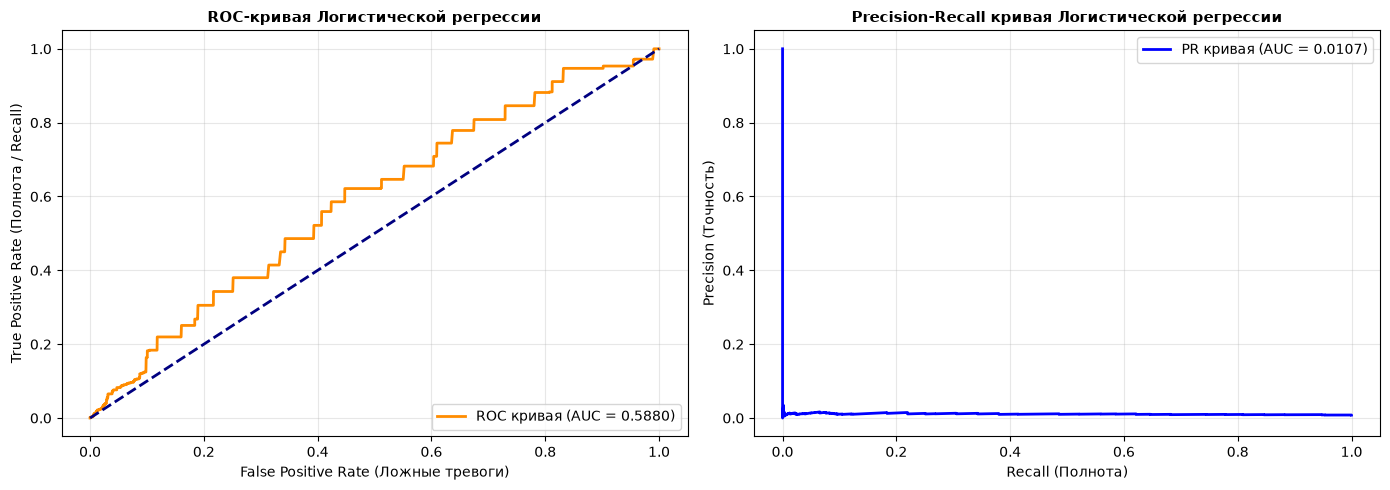

In [7]:
# ОБУЧЕНИЕ, ВЕСА ПРИЗНАКОВ И ГРАФИКИ ROC / PR 

# Обучаем модель логистической регрессии
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_train_res)

# Анализируем коэффициенты (веса) и отношение шансов (Odds Ratio)
weights = log_reg.coef_[0]
coef_df = pd.DataFrame({
    'Признак': features,
    'Коэффициент (Вес)': weights,
    'Odds Ratio (e^w)': np.exp(weights)
}).sort_values(by='Коэффициент (Вес)', ascending=False)

print("--- Влияние физических факторов на риск отказа оборудования ---")
display(coef_df.round(4))

# Получаем вероятности класса 1 на тестовой выборке
y_scores = log_reg.predict_proba(X_test_scaled)[:, 1]

# Строим кривые ROC и Precision-Recall
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# ROC-кривая (индекс 0)
fpr, tpr, _ = roc_curve(y_test, y_scores)
roc_auc = auc(fpr, tpr)
ax[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC кривая (AUC = {roc_auc:.4f})')
ax[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[0].set_xlabel('False Positive Rate (Ложные тревоги)')
ax[0].set_ylabel('True Positive Rate (Полнота / Recall)')
ax[0].set_title('ROC-кривая Логистической регрессии', fontsize=11, fontweight='bold')
ax[0].legend(loc="lower right")
ax[0].grid(True, alpha=0.3)

# Precision-Recall кривая (индекс 1)
precision, recall, _ = precision_recall_curve(y_test, y_scores)
pr_auc = auc(recall, precision)
ax[1].plot(recall, precision, color='blue', lw=2, label=f'PR кривая (AUC = {pr_auc:.4f})')
ax[1].set_xlabel('Recall (Полнота)')
ax[1].set_ylabel('Precision (Точность)')
ax[1].set_title('Precision-Recall кривая Логистической регрессии', fontsize=11, fontweight='bold')
ax[1].legend(loc="upper right")
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


• Главный драйвер поломок — start_count (Вес = 0.1843, Odds Ratio = 1.2024): Каждый рост частоты запусков на одно стандартное отклонение увеличивает шансы отказа оборудования в ближайшие 24 часа на 20,2%.
• Второй по значимости фактор — rpm_std (Вес = 0.0793, Odds Ratio = 1.0825): Рост нестабильности оборотов увеличивает риск поломки на 8,25%.
• Все остальные факторы (power_avg, vib_std, temp_std) также имеют положительные веса, рост энергопотребления, вибрации и скачков температуры повышает риск аварии.

Оптимальный порог по максимуму F1-меры: 0.10 (F1 = 0.0250)

--- ОТЧЕТ ПО МЕТРИКАМ КАЧЕСТВА (Порог = 0.1) ---
              precision    recall  f1-score   support

   Норма (0)       0.99      0.89      0.94     78462
   Отказ (1)       0.01      0.18      0.03       642

    accuracy                           0.88     79104
   macro avg       0.50      0.54      0.48     79104
weighted avg       0.98      0.88      0.93     79104



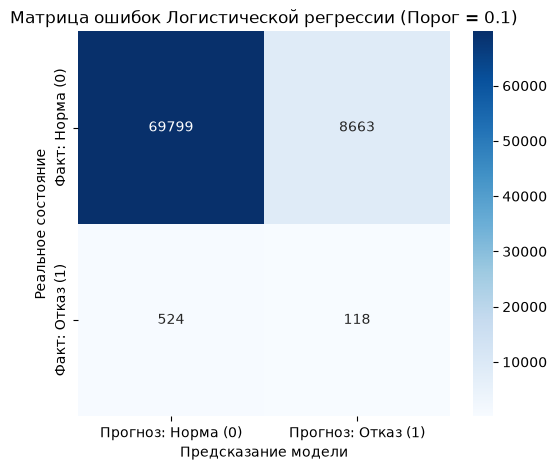

In [8]:
# ВЫБОР ПОРОГА, МАТРИЦА ОШИБОК И МЕТРИКИ КАЧЕСТВА

# Перебираем пороги от 0.05 до 0.90, чтобы найти оптимальный по F1-мере
thresholds = np.arange(0.05, 0.90, 0.01)
f1_scores = [f1_score(y_test, (y_scores >= t).astype(int), zero_division=0) for t in thresholds]
best_idx = np.argmax(f1_scores)
best_thresh = thresholds[best_idx]

print(f"Оптимальный порог по максимуму F1-меры: {best_thresh:.2f} (F1 = {f1_scores[best_idx]:.4f})")

# Используем найденный порог для финального прогноза
chosen_threshold = round(best_thresh, 2)
y_pred = (y_scores >= chosen_threshold).astype(int)

print(f"\n--- ОТЧЕТ ПО МЕТРИКАМ КАЧЕСТВА (Порог = {chosen_threshold}) ---")
print(classification_report(y_test, y_pred, target_names=['Норма (0)', 'Отказ (1)'], zero_division=0))

# Строим матрицу ошибок
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Прогноз: Норма (0)', 'Прогноз: Отказ (1)'],
            yticklabels=['Факт: Норма (0)', 'Факт: Отказ (1)'])
plt.ylabel('Реальное состояние')
plt.xlabel('Предсказание модели')
plt.title(f'Матрица ошибок Логистической регрессии (Порог = {chosen_threshold})')
plt.show()



Выводы по задаче логистической регрессии


1. Анализ качества модели и сравнение с KNN
• Улучшение разделяющей способности: Логистическая регрессия продемонстрировала ROC-AUC = 0.5880 (против 0.5066 у KNN), уверенно превзойдя уровень случайного угадывания.
• Рост полноты (Recall): При оптимальном пороге классификации модель смогла заранее обнаружить 118 реальных отказов из 642 на тестовой выборке (Recall = 18%), что в два раза лучше результата модели KNN (56 обнаруженных отказов, Recall = 9%).
• Ограничения линейной модели: Несмотря на прогресс, итоговая F1-мера для целевого класса остается невысокой (0.03), а модель генерирует 8663 ложных срабатывания (Precision = 1%). Это объясняется дисбалансом классов.

2. Обоснование выбора порога предсказания (Y = 1)
• Стандартный порог вероятности 0.5 для данной задачи неприменим: так как обучающая выборка была сбалансирована методом Random Undersampling в пропорции 1:10 (~9% отказов), предсказанные вероятности для редких событий концентрируются в нижней части шкалы.
• Путем перебора порогов по сетке был выбран порог 0.10, максимизирующий метрику F1-score.

3. Интерпретация полученных зависимостей
Благодаря предварительному масштабированию признаков, веса модели напрямую отражают силу влияния факторов на риск отказа:
• Главный фактор риска — частота запусков (start_count, вес = 0.1843, Odds Ratio = 1.2024): Увеличение интенсивности циклов «старт-стоп» на одно стандартное отклонение повышает шансы поломки оборудования в ближайшие 24 часа на 20,2%. Это подтверждает гипотезу о разрушительном влиянии пиковых пусковых токов и переходных режимов.
• Второй по значимости фактор — волатильность оборотов (rpm_std, вес = 0.0793, Odds Ratio = 1.0825): Рост нестабильности скорости вращения повышает шансы отказа на 8,25%, сигнализируя о механическом люфте и износе подшипников.
• Влияние нагрузки и вибрации (power_avg, vib_std, temp_std): Все признаки имеют положительные коэффициенты, подтверждая прямую связь между ростом энергопотребления, вибрации, температурных скачков и вероятностью выхода станка из строя.